# Exploring PDF Libraries and Rule-Based Parsing

A practical comparison of **pypdf**, **pdfplumber**, and **PyMuPDF**, followed by simple PDF section/phone-number extraction and visual highlighting.

**Privacy:** The original notebook used personal resumes and printed personal information. This public version works on `sample_resume.pdf`, a fictional PDF written specifically for this demonstration.

## 1. Setup

In [1]:
from pathlib import Path
import re
import numpy as np
import cv2
from pypdf import PdfReader
import pdfplumber
import pymupdf
from PIL import Image
from IPython.display import display

pdf_path = Path("sample_resume.pdf")
if not pdf_path.exists():
    raise FileNotFoundError(f"Required synthetic example is missing: {pdf_path}")

## 2. `pypdf`: reading pages and text

The original notebook used the older `PyPDF2` package. This public version uses its maintained successor `pypdf`.

In [2]:
reader = PdfReader(str(pdf_path))
print("Pages:", len(reader.pages))
for page_number, page in enumerate(reader.pages, start=1):
    print(f"Page {page_number} (first 220 characters):")
    print((page.extract_text() or "")[:220])

Pages: 2
Page 1 (first 220 characters):
Jordan Example
Winnipeg, MB | jordan@example.invalid | 204-555-0182
PROFILE
Developer interested in document parsing and Python automation.
CORE TECHNICAL SKILLS
Python, JavaScript, SQL, Git, PDF text extraction.
PROFESS
Page 2 (first 220 characters):
ADDITIONAL NOTES
This is a fictional example. It contains no real person data.



## 3. `pdfplumber`: text and potential table extraction

Not every document contains tables. This sample resume does not.

In [3]:
with pdfplumber.open(pdf_path) as pdf:
    first_page = pdf.pages[0]
    print("Text preview:", (first_page.extract_text() or "")[:220])
    print("Tables found:", len(first_page.extract_tables()))

Text preview: Jordan Example
Winnipeg, MB | jordan@example.invalid | 204-555-0182
PROFILE
Developer interested in document parsing and Python automation.
CORE TECHNICAL SKILLS
Python, JavaScript, SQL, Git, PDF text extraction.
PROFESS
Tables found: 0


## 4. PyMuPDF: metadata, spans and text positions

In [4]:
doc = pymupdf.open(pdf_path)
print("Metadata title:", doc.metadata.get("title"))
page = doc[0]
print("Text preview:", page.get_text("text")[:220])

spans = []
for block in page.get_text("dict").get("blocks", []):
    for line in block.get("lines", []):
        for span in line.get("spans", []):
            spans.append((span["text"], tuple(round(v, 1) for v in span["bbox"])))
print("First text spans with coordinates:")
for sample in spans[:4]:
    print(sample)

Metadata title: Synthetic resume for public parsing notebook
Text preview: Jordan Example
Winnipeg, MB | jordan@example.invalid | 204-555-0182
PROFILE
Developer interested in document parsing and Python automation.
CORE TECHNICAL SKILLS
Python, JavaScript, SQL, Git, PDF text extraction.
PROFESS
First text spans with coordinates:
('Jordan Example', (62.0, 28.8, 193.3, 52.2))
('Winnipeg, MB | jordan@example.invalid | 204-555-0182', (62.0, 54.2, 309.7, 68.0))
('PROFILE', (62.0, 87.2, 114.0, 103.7))
('Developer interested in document parsing and Python automation.', (68.0, 108.2, 361.5, 122.0))


## 5. Clip text between two role headings

This technique depends on the target headings being present and appearing in the expected order.

In [5]:
start_matches = page.search_for("Full Stack Developer Intern")
end_matches = page.search_for("Freelance Full-Stack Developer")
if start_matches and end_matches and start_matches[0].y0 < end_matches[0].y0:
    clip = pymupdf.Rect(page.rect.x0, start_matches[0].y0, page.rect.x1, end_matches[0].y0)
    print(page.get_text("text", clip=clip).strip())
else:
    print("Target headings not found in the expected order.")

Full Stack Developer Intern
Built sample API features, tested endpoints, documented results.


## 6. Parse known document sections

This rule-based example recognizes **exactly matching** section headings. It is not a universal resume parser.

In [6]:
headings = {
    "PROFILE", "CORE TECHNICAL SKILLS", "PROFESSIONAL EXPERIENCE",
    "SOFTWARE PROJECT", "EDUCATION AND CERTIFICATIONS"
}
text = "\n".join(p.get_text("text", sort=True) for p in doc)
sections = {}
current = "HEADER"
for raw_line in text.splitlines():
    line = raw_line.strip()
    if not line:
        continue
    if line in headings:
        current = line
        sections.setdefault(current, [])
    else:
        sections.setdefault(current, []).append(line)
for section, lines in sections.items():
    print(f"{section}: {len(lines)} lines")

HEADER: 2 lines
PROFILE: 1 lines
CORE TECHNICAL SKILLS: 1 lines
PROFESSIONAL EXPERIENCE: 4 lines
SOFTWARE PROJECT: 1 lines
EDUCATION AND CERTIFICATIONS: 3 lines


## 7. Locate and highlight a phone number

Use `page.search_for()` for the entire matched string rather than assuming it is a single token. For this unrotated sample, PyMuPDF coordinates have their origin at the top left; a 1.5× rendering requires scaling each coordinate by 1.5.

Synthetic phone number found: 204-555-0182 | match rectangles: 1


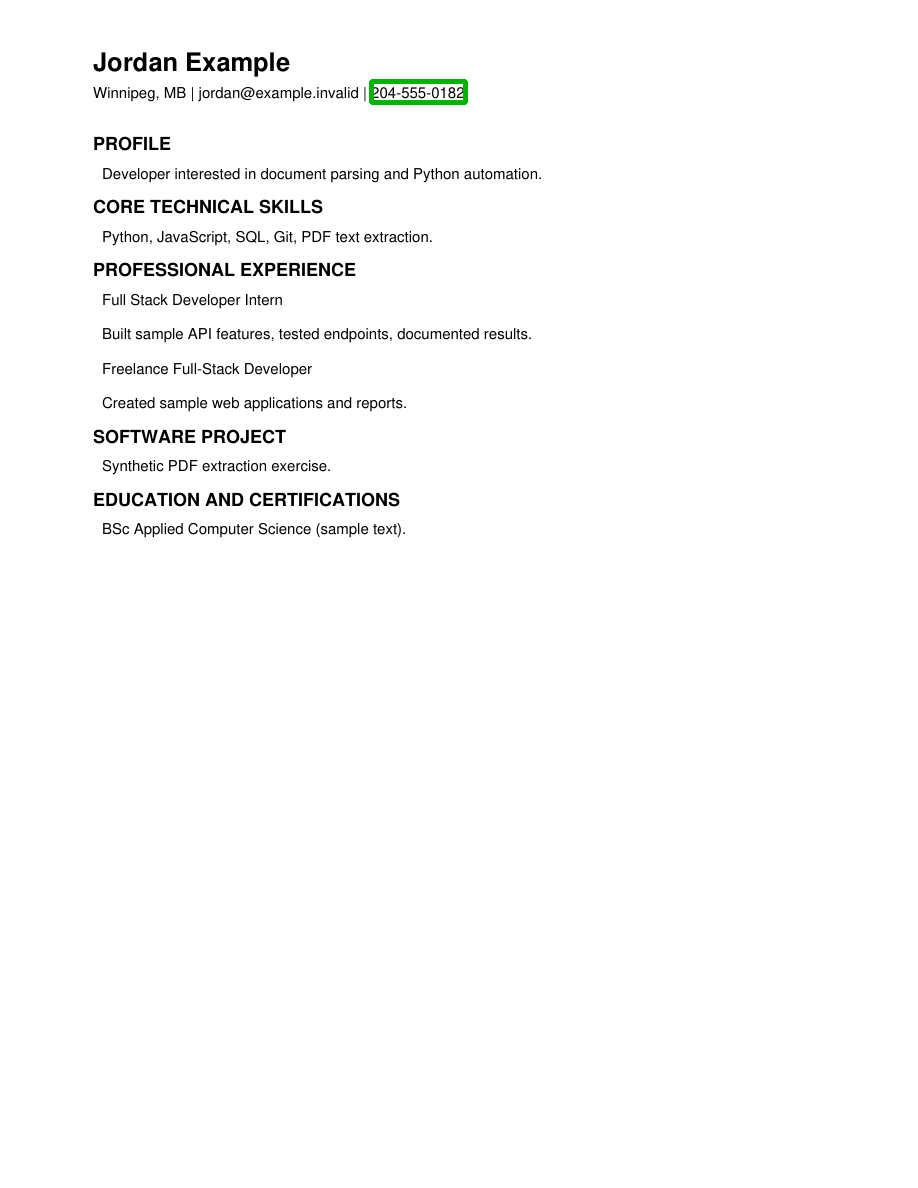

In [7]:
phone_match = re.search(r"\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}", page.get_text("text"))
if phone_match:
    target = phone_match.group(0)
    rects = page.search_for(target)
    print("Synthetic phone number found:", target, "| match rectangles:", len(rects))
else:
    target, rects = None, []
    print("No phone number found")

zoom = 1.5
pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, 3).copy()
for rect in rects:
    x0, y0, x1, y1 = (round(rect.x0 * zoom), round(rect.y0 * zoom),
                      round(rect.x1 * zoom), round(rect.y1 * zoom))
    cv2.rectangle(img, (x0, y0), (x1, y1), (0, 180, 0), 3)
display(Image.fromarray(img))

## 8. Cleanup and takeaways

- `pypdf` supports straightforward page/text access.
- `pdfplumber` has useful table/layout inspection functions.
- PyMuPDF supports text coordinate search and page rendering.
- The rule-based parser needs changes for new heading styles, PDFs with multiple columns, and scans.

This demonstrates parsing and annotation, not a production-ready or AI-based resume screening tool.

In [8]:
doc.close()
print("PDF closed.")

PDF closed.
